# LHS15 Shared Initial Objectives

Inspect the objective values of the first 15 shared initial points for each seed. This notebook is analysis-only: it reads `experiments/online_lhs15_shared_init/initial_designs/seed*.json` and cached touchstone files, then evaluates the same BCLF objective used by the online runner.

In [1]:
from __future__ import annotations

from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display


def find_repo_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / "src").exists() and (path / "experiments").exists():
            return path
    raise FileNotFoundError(f"Could not find repo root from {start}")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from optimization import BCLFOptimizationSpec  # noqa: E402

try:  # noqa: E402
    from src.complex_func import FunctionFromTouchstone
except ImportError:  # noqa: E402
    from complex_func import FunctionFromTouchstone


RESULT_ROOT = REPO_ROOT / "experiments" / "online_lhs15_shared_init"
INITIAL_DESIGN_DIR = RESULT_ROOT / "initial_designs"
OUTPUT_DIR = REPO_ROOT / "experiments" / "online_lhs15_shared_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
N_INIT = 15

SPEC = BCLFOptimizationSpec(
    passband_ghz=(4.8, 5.4),
    lower_stopband_ghz=(3.6, 4.4),
    upper_stopband_ghz=(5.8, 8.7),
    min_passband_s21_db=-5.0,
    max_passband_s11_db=-7.0,
    max_stopband_s21_db=-15.0,
    s11_weight=0.5,
    stopband_weight=0.5,
)

plt.style.use("seaborn-v0_8-whitegrid")

print(f"repo root: {REPO_ROOT}")
print(f"initial designs: {INITIAL_DESIGN_DIR}")
print(f"output: {OUTPUT_DIR}")

repo root: /home/zhanghf/projects/vector
initial designs: /home/zhanghf/projects/vector/experiments/online_lhs15_shared_init/initial_designs
output: /home/zhanghf/projects/vector/experiments/online_lhs15_shared_comparison


## Evaluate Cached Initial Points

In [2]:
def relative_to_repo(path: Path) -> str:
    return str(path.resolve().relative_to(REPO_ROOT))


def resolve_repo_path(path_text: str | Path) -> Path:
    path = Path(path_text)
    return path if path.is_absolute() else REPO_ROOT / path


def load_touchstone(path: Path) -> tuple[np.ndarray, np.ndarray]:
    parser = FunctionFromTouchstone(port_num=2)
    parser.parse(str(path))
    return np.asarray(parser.freq, dtype=float), np.asarray(parser.evaluate_all(), dtype=complex)


def evaluate_touchstone(path: Path) -> dict[str, object]:
    freqs, s_params = load_touchstone(path)
    result = SPEC.evaluate(freqs, s_params)
    row: dict[str, object] = {
        "objective": float(result.scalar_objective()),
    }
    row.update({f"metric_{key}": float(value) for key, value in result.metrics.items()})
    row.update({f"objective_component_{key}": float(value) for key, value in result.objective_components.items()})
    metadata = dict(result.metadata or {})
    row["feasible"] = metadata.get("feasible")
    row["constraint_margin_min"] = metadata.get("constraint_margin_min")
    for key, value in dict(metadata.get("constraint_metrics", {})).items():
        row[f"constraint_metric_{key}"] = float(value)
    for key, value in dict(metadata.get("constraint_violations", {})).items():
        row[f"constraint_violation_{key}"] = float(value)
    return row


def load_initial_objectives() -> pd.DataFrame:
    manifest_paths = sorted(INITIAL_DESIGN_DIR.glob("seed*.json"))
    if not manifest_paths:
        raise FileNotFoundError(f"No initial design manifests found in {INITIAL_DESIGN_DIR}")

    rows: list[dict[str, object]] = []
    for manifest_path in manifest_paths:
        payload = json.loads(manifest_path.read_text(encoding="utf-8"))
        seed = int(payload["seed"])
        cache_dir = resolve_repo_path(payload["cache_dir"])
        selected_rows = list(payload.get("selected", []))[:N_INIT]
        for selected in selected_rows:
            touchstone_path = cache_dir / str(selected["cache_filename"])
            base = {
                "seed": seed,
                "initial_index": int(selected["initial_index"]),
                "trial": int(selected["initial_index"]) + 1,
                "geometry": selected["geometry"],
                "L": selected["variables"].get("L"),
                "L1": selected["variables"].get("L1"),
                "L2": selected["variables"].get("L2"),
                "W": selected["variables"].get("W"),
                "W1": selected["variables"].get("W1"),
                "W2": selected["variables"].get("W2"),
                "S1": selected["variables"].get("S1"),
                "S2": selected["variables"].get("S2"),
                "nearest_distance_normalized": float(selected["nearest_distance_normalized"]),
                "manifest_path": relative_to_repo(manifest_path),
                "touchstone_path": relative_to_repo(touchstone_path),
                "cache_exists": touchstone_path.exists(),
            }
            if not touchstone_path.exists():
                rows.append(base)
                continue
            base.update(evaluate_touchstone(touchstone_path))
            rows.append(base)
    df = pd.DataFrame(rows).sort_values(["seed", "initial_index"]).reset_index(drop=True)
    return df


objective_df = load_initial_objectives()
objective_path = OUTPUT_DIR / "lhs15_initial_objectives.csv"
objective_df.to_csv(objective_path, index=False)

display_columns = [
    "seed",
    "trial",
    "objective",
    "feasible",
    "constraint_margin_min",
    "nearest_distance_normalized",
    "L",
    "L1",
    "L2",
    "W",
    "W1",
    "W2",
    "S1",
    "S2",
]
display(objective_df[[col for col in display_columns if col in objective_df.columns]])
print(f"wrote: {relative_to_repo(objective_path)}")

,seed,trial,objective,feasible,constraint_margin_min,nearest_distance_normalized,L,L1,L2,W,W1,W2,S1,S2
0,0,1,27.896200,None,None,0.340439,7.78,8.04,7.95,1.08,0.84,1.05,0.14,0.59
1,0,2,11.090122,None,None,0.286590,7.85,8.19,7.85,1.01,0.81,0.97,0.15,0.56
2,0,3,67.203102,None,None,0.346708,7.79,8.03,7.82,0.97,0.71,1.02,0.15,0.57
3,0,4,34.329937,None,None,0.273571,7.86,8.17,7.87,1.02,0.73,1.10,0.13,0.58
4,0,5,17.899410,None,None,0.358035,7.75,8.12,7.82,0.95,0.74,0.94,0.15,0.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,4,11,33.763131,None,None,0.252583,7.75,8.11,7.85,1.09,0.76,1.01,0.15,0.56
71,4,12,38.697762,None,None,0.471744,7.79,8.03,7.85,1.00,0.82,1.04,0.16,0.56
72,4,13,29.860191,None,None,0.458597,7.74,8.10,7.93,1.08,0.75,0.98,0.14,0.58
73,4,14,11.628204,None,None,0.357290,7.89,8.16,7.95,0.96,0.76,0.99,0.14,0.56


wrote: experiments/online_lhs15_shared_comparison/lhs15_initial_objectives.csv


## Summary

In [3]:
summary_df = (
    objective_df.groupby("seed", observed=True)
    .agg(
        n=("objective", "count"),
        min_objective=("objective", "min"),
        median_objective=("objective", "median"),
        mean_objective=("objective", "mean"),
        max_objective=("objective", "max"),
        best_initial_index=("objective", lambda values: int(objective_df.loc[values.idxmin(), "initial_index"])),
        median_lhs_distance=("nearest_distance_normalized", "median"),
    )
    .reset_index()
)

best_rows_df = objective_df.loc[objective_df.groupby("seed")["objective"].idxmin()].copy()
summary_path = OUTPUT_DIR / "lhs15_initial_objective_summary.csv"
best_rows_path = OUTPUT_DIR / "lhs15_initial_best_by_seed.csv"
summary_df.to_csv(summary_path, index=False)
best_rows_df.to_csv(best_rows_path, index=False)

display(summary_df)
display(best_rows_df[["seed", "trial", "objective", "geometry", "touchstone_path"]])
print(f"wrote: {relative_to_repo(summary_path)}")
print(f"wrote: {relative_to_repo(best_rows_path)}")

,seed,n,min_objective,median_objective,mean_objective,max_objective,best_initial_index,median_lhs_distance
0,0,15,-2.504020,24.725200,30.172839,79.553398,8,0.347884
1,1,15,-8.052391,43.695696,42.487779,131.268212,12,0.346284
2,2,15,-14.462659,30.152318,31.473759,78.492057,7,0.391636
3,3,15,-14.512862,25.774464,29.719918,76.383778,4,0.355230
4,4,15,-16.313817,29.860191,41.745717,149.478393,2,0.381795


,seed,trial,objective,geometry,touchstone_path
8,0,9,-2.504020,"[7.88, 8.02, 7.99, 1.06, 0.76, 1.02, 0.14, 0.59]",data/bandpass_coupled_line_filter_export/ext/B...
27,1,13,-8.052391,"[7.82, 8.09, 7.92, 1.04, 0.9, 1.01, 0.14, 0.59]",data/bandpass_coupled_line_filter_export/ext/B...
37,2,8,-14.462659,"[7.88, 8.18, 7.94, 1.0, 0.9, 0.94, 0.15, 0.58]",data/bandpass_coupled_line_filter_export/ext/B...
49,3,5,-14.512862,"[7.87, 8.02, 7.85, 1.08, 0.85, 1.02, 0.15, 0.56]",data/bandpass_coupled_line_filter_export/ext/B...
62,4,3,-16.313817,"[7.82, 8.1, 7.94, 0.97, 0.74, 1.08, 0.13, 0.58]",data/bandpass_coupled_line_filter_export/ext/B...


wrote: experiments/online_lhs15_shared_comparison/lhs15_initial_objective_summary.csv
wrote: experiments/online_lhs15_shared_comparison/lhs15_initial_best_by_seed.csv


## Plots

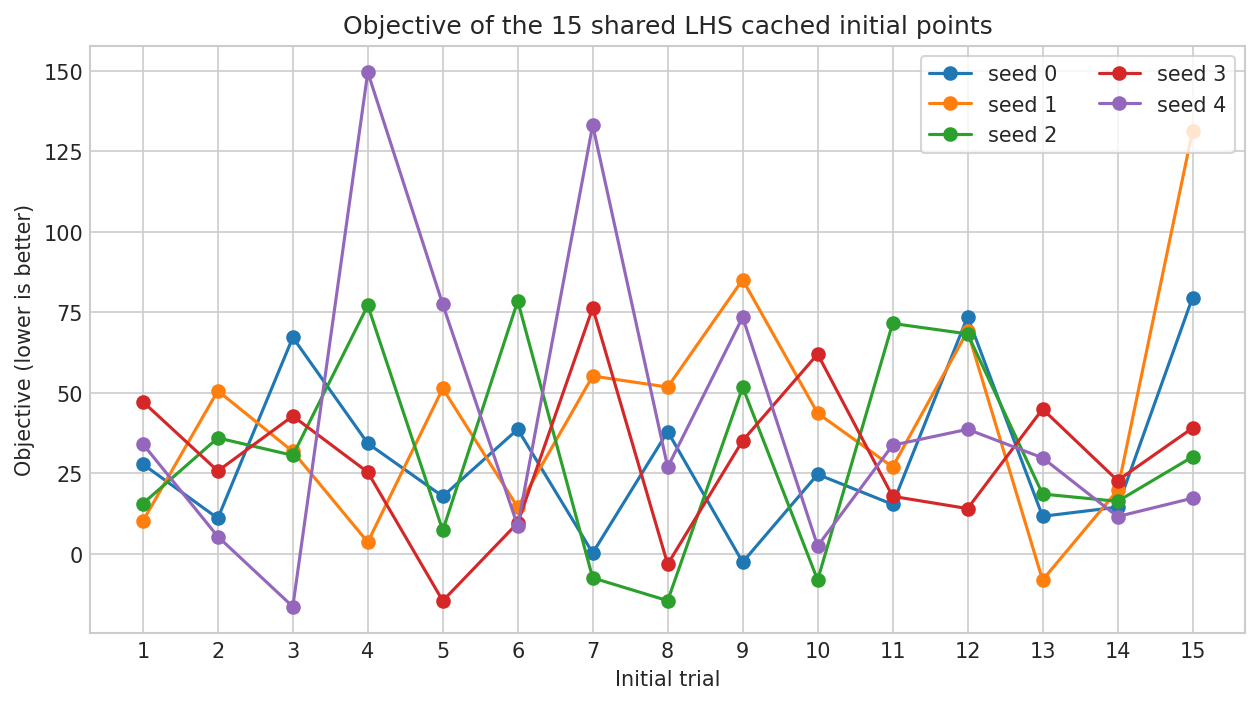

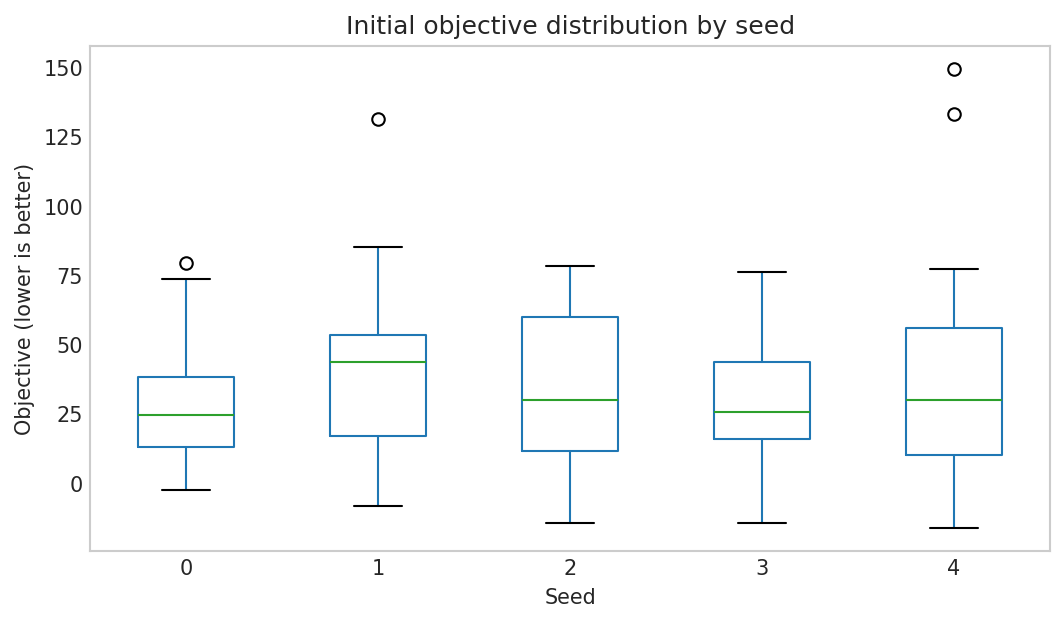

wrote: experiments/online_lhs15_shared_comparison/lhs15_initial_objectives_by_trial.png
wrote: experiments/online_lhs15_shared_comparison/lhs15_initial_objectives_by_seed.png


In [4]:
line_plot_path = OUTPUT_DIR / "lhs15_initial_objectives_by_trial.png"
box_plot_path = OUTPUT_DIR / "lhs15_initial_objectives_by_seed.png"

fig, ax = plt.subplots(figsize=(8.5, 4.8), dpi=150)
for seed, group in objective_df.groupby("seed"):
    group = group.sort_values("initial_index")
    ax.plot(group["trial"], group["objective"], marker="o", linewidth=1.5, label=f"seed {seed}")
ax.set_title("Objective of the 15 shared LHS cached initial points")
ax.set_xlabel("Initial trial")
ax.set_ylabel("Objective (lower is better)")
ax.set_xticks(np.arange(1, N_INIT + 1))
ax.legend(frameon=True, ncol=2)
fig.tight_layout()
fig.savefig(line_plot_path, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.4), dpi=150)
objective_df.boxplot(column="objective", by="seed", ax=ax, grid=False)
ax.set_title("Initial objective distribution by seed")
ax.figure.suptitle("")
ax.set_xlabel("Seed")
ax.set_ylabel("Objective (lower is better)")
fig.tight_layout()
fig.savefig(box_plot_path, bbox_inches="tight")
plt.show()

print(f"wrote: {relative_to_repo(line_plot_path)}")
print(f"wrote: {relative_to_repo(box_plot_path)}")

## Optional: Compare Against Method Artifacts

If any BO/LHS/Turbo/BNN runs have already produced JSON/CSV/checkpoint artifacts, this cell checks whether their first 15 recorded objectives match the shared cached objective table.

In [5]:
METHOD_CONFIG = {
    "BO": {"root": RESULT_ROOT / "bo", "stem": "bo_lhs15_shared"},
    "LHS": {"root": RESULT_ROOT / "lhs", "stem": "lhs_lhs15_shared"},
    "Turbo": {"root": RESULT_ROOT / "turbo", "stem": "turbo_lhs15_shared"},
    "BNN": {"root": RESULT_ROOT / "bnn", "stem": "bnn_lhs15_shared"},
}


def load_method_history(root: Path, stem: str, seed: int) -> pd.DataFrame | None:
    csv_path = root / f"{stem}_seed{seed}.csv"
    json_path = root / f"{stem}_seed{seed}.json"
    checkpoint_path = root / f"{stem}_seed{seed}.checkpoint.json"
    if csv_path.exists():
        return pd.read_csv(csv_path)
    for path in (json_path, checkpoint_path):
        if path.exists():
            payload = json.loads(path.read_text(encoding="utf-8"))
            rows = payload.get("trials")
            if rows is None:
                rows = payload.get("history", [])
            return pd.DataFrame(rows)
    return None


method_rows = []
for method, config in METHOD_CONFIG.items():
    for seed in sorted(objective_df["seed"].unique()):
        history = load_method_history(Path(config["root"]), str(config["stem"]), int(seed))
        if history is None or history.empty:
            continue
        first = history.loc[pd.to_numeric(history["iteration"], errors="coerce") < N_INIT].copy()
        first["method"] = method
        first["seed"] = int(seed)
        first["initial_index"] = pd.to_numeric(first["iteration"], errors="coerce").astype(int)
        first["method_objective"] = pd.to_numeric(first["objective"], errors="coerce")
        method_rows.append(first[["method", "seed", "initial_index", "method_objective"]])

if not method_rows:
    print("No method artifacts found yet. Run this cell again after online jobs produce JSON/CSV/checkpoints.")
else:
    method_first15_df = pd.concat(method_rows, ignore_index=True)
    check_df = method_first15_df.merge(
        objective_df[["seed", "initial_index", "objective"]],
        on=["seed", "initial_index"],
        how="left",
    )
    check_df["abs_delta_vs_cache_objective"] = (check_df["method_objective"] - check_df["objective"]).abs()
    check_path = OUTPUT_DIR / "lhs15_initial_method_objective_check.csv"
    check_df.to_csv(check_path, index=False)
    display(check_df.sort_values(["method", "seed", "initial_index"]))
    display(
        check_df.groupby("method")[["abs_delta_vs_cache_objective"]]
        .agg(["count", "max", "median"])
        .reset_index()
    )
    print(f"wrote: {relative_to_repo(check_path)}")

No method artifacts found yet. Run this cell again after online jobs produce JSON/CSV/checkpoints.
